# Предобработка данных и инженерия признаков

В этом исследовании подготовим исходные характеристики недвижимости к построению моделей. Сохраним связь между регрессией и классификацией, рассмотрим способы заполнения пропусков, обработки выбросов и создания новых признаков. Обучаемые преобразования будут подбираться только на тренировочной выборке.

## Подготовка окружения и загрузка данных

При выполнении Notebook используется тот же модуль `house_prices_ai`, что и при запуске через командную строку. Исходный `train.csv` не изменяется.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, display

# Определяем корень проекта независимо от каталога запуска.
ROOT = next(
    (
        path for path in (Path.cwd(), Path.cwd().parent)
        if (path / "house_prices_ai").is_dir()
    ),
    None
)

if ROOT is None:
    raise RuntimeError(
        "Не найден корень проекта House Prices AI"
    )

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from house_prices_ai.config import (
    RAW_TRAIN_FILE,
    OUTPUT_DIR,
    PROCESSED_DATA_DIR,
)
from house_prices_ai.data_loader import load_training_data
from house_prices_ai.preprocessing import (
    run_preprocessing,
    CLASS_THRESHOLD,
)

df = load_training_data(RAW_TRAIN_FILE)

print(f"Объектов: {len(df)}. Столбцов: {df.shape[1]}")
print(f"Пропущенных ячеек: {int(df.isna().sum().sum())}")

Объектов: 1460. Столбцов: 81
Пропущенных ячеек: 6965


## Цели регрессии и классификации

Для регрессии целевой переменной остаётся `SalePrice` (цена продажи в долларах). Для классификации используем порог $200 000.
Класс `0` обозначает объекты дешевле этой суммы, класс `1` — объекты стоимостью от $200 000.

В матрицу входных признаков не включаем цену продажи и `Id` (идентификатор записи). Разделение обучающей и тестовой частей проводится один раз, одинаково для обеих задач.

In [2]:
balance = (df["SalePrice"] >= CLASS_THRESHOLD).astype(int).value_counts().sort_index()
display(pd.DataFrame({"Число объектов": balance, "Доля, %": (balance / len(df) * 100).round(1)}))

,Число объектов,"Доля, %"
SalePrice,,
0,1025,70.2
1,435,29.8


## Выполнение предобработки

Обработка пропусков учитывает смысл признаков. Например, пустое значение `GarageType` (тип гаража) описывает отсутствие гаража, а неизвестная ширина участка `LotFrontage` заполняется медианой, вычисленной по обучающей выборке.

Для шести непрерывных характеристик применяется ограничение крайних значений по правилу 1,5 IQR. Границы рассчитываются только на обучающей выборке и затем без изменений применяются к тестовой. Это осознанное допущение, а не доказательство ошибочности дорогих или больших домов. При сравнении моделей потребуется проверить, как ограничение влияет на точность прогнозов.

In [3]:
result = run_preprocessing(RAW_TRAIN_FILE, OUTPUT_DIR / "preprocessing", PROCESSED_DATA_DIR)
print("Подготовка завершена")
print(f"Обучающая выборка: {result.train_rows} строк")
print(f"Тестовая выборка: {result.test_rows} строк")
print(f"Признаков после кодирования: {result.features_count}")
print(f"Отчёт: {result.report_path}")

Подготовка завершена
Обучающая выборка: 1168 строк
Тестовая выборка: 292 строк
Признаков после кодирования: 316
Отчёт: F:\JetBrainsProjects\PycharmProjects\house-prices-ai\outputs\preprocessing\preprocessing_summary.md


### Пропуски в обучающей выборке

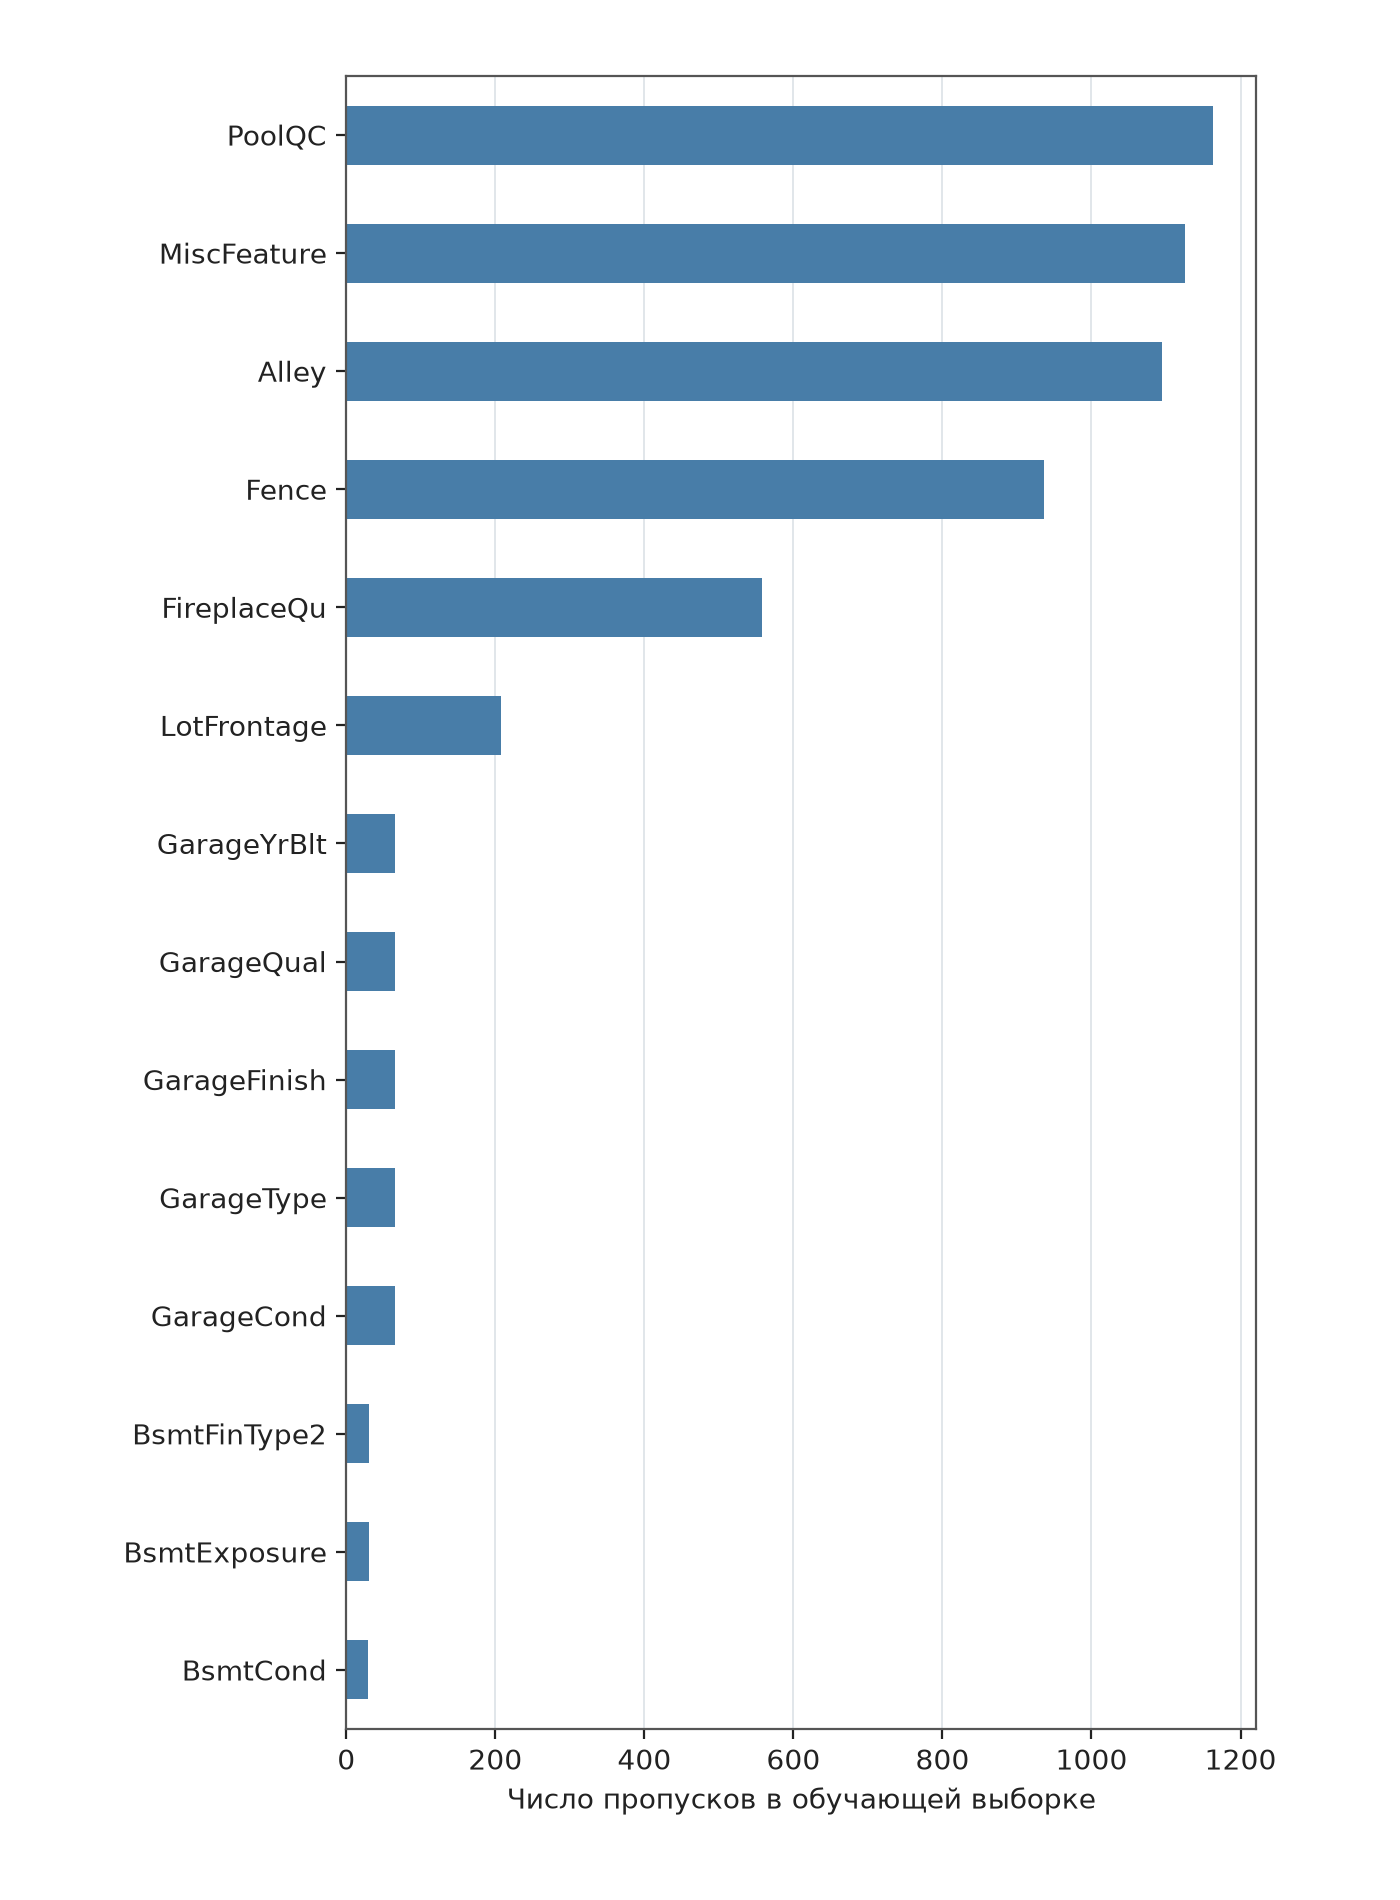

In [4]:
display(Image(filename=str(result.generated_plots["missing"])))

*Рисунок 2.1 — Распределение пропущенных значений по характеристикам недвижимости.*

Пропуски наиболее характерны для признаков, описывающих дополнительные элементы дома и участка. При подготовке данных важно не смешивать отсутствие объекта с неизвестным значением. Медиана и константы определяются на тренировочных строках, поэтому тестовая выборка не влияет на выбор способа заполнения.

### Сколько значений изменено при обработке выбросов

Количество потенциальных выбросов, найденных по правилу IQR, не равно числу удалённых домов. Мы не удаляем наблюдения, а ограничиваем только шесть непрерывных характеристик. В следующей таблице показаны нижняя и верхняя границы, количество значений, попавших за эти границы, и доля фактически изменённых ячеек. Результаты рассчитаны отдельно для обучающей и тестовой выборок.

In [5]:
outlier_changes = pd.read_csv(OUTPUT_DIR / "preprocessing" / "outlier_changes.csv")
display(outlier_changes[["Выборка", "Признак", "Ниже границы", "Выше границы",
                         "Всего изменено", "Доля изменённых, %"]])
for split in ("train", "test"):
    changed = int(outlier_changes.loc[outlier_changes["Выборка"] == split, "Всего изменено"].sum())
    print(f"{split}: скорректировано {changed} значений в выбранных признаках")

,Выборка,Признак,Ниже границы,Выше границы,Всего изменено,"Доля изменённых, %"
0,train,LotArea,1,51,52,4.45
1,train,GrLivArea,0,27,27,2.31
2,train,TotalBsmtSF,0,21,21,1.80
3,train,GarageArea,0,20,20,1.71
4,train,1stFlrSF,0,19,19,1.63
5,train,2ndFlrSF,0,2,2,0.17
6,test,LotArea,0,15,15,5.14
7,test,GrLivArea,0,4,4,1.37
8,test,TotalBsmtSF,0,3,3,1.03
9,test,GarageArea,0,1,1,0.34


train: скорректировано 141 значений в выбранных признаках
test: скорректировано 25 значений в выбранных признаках


Значения ограничивались границами, определёнными только на обучающих объектах. Благодаря этому при предобработке тестовые цены и характеристики не влияют на выбор границ. При этом большие площади могут быть реальными особенностями недвижимости, поэтому окончательную пользу такой обработки мы проверим при сравнении моделей с ограничением и без него.

## Кодирование и масштабирование

Номинальные категории, например `Neighborhood` (район), преобразуются методом One-Hot Encoding. Числовые характеристики стандартизируются. В результате их значения выражаются в сопоставимом масштабе. Колонки `MSSubClass` (тип здания) обрабатываются как категории, несмотря на числовые коды.

Это особенно важно для моделей, чувствительных к разным масштабам, в том числе линейной регрессии и нейросетей.

In [6]:
x_train = pd.read_csv(PROCESSED_DATA_DIR / "X_train_reg.csv")
x_test = pd.read_csv(PROCESSED_DATA_DIR / "X_test_reg.csv")
print(f"Размерность: train {x_train.shape}, test {x_test.shape}")
print(f"Пропусков после обработки: {int(x_train.isna().sum().sum()) + int(x_test.isna().sum().sum())}")
print(f"Колонки совпадают: {x_train.columns.equals(x_test.columns)}")
display(x_train.iloc[:5, :8])

Размерность: train (1168, 316), test (292, 316)
Пропусков после обработки: 0
Колонки совпадают: True


,num__LotFrontage,num__LotArea,num__OverallQual,num__OverallCond,num__YearBuilt,num__YearRemodAdd,num__MasVnrArea,num__BsmtFinSF1
0,1.650612,1.635021,-0.074699,-0.533044,1.151933,1.018960,-0.569186,-0.963901
1,-0.029651,0.153706,-0.795759,-0.533044,-0.301366,-1.119665,-0.569186,0.718887
2,0.110371,-0.277759,0.646361,-0.533044,1.251022,1.164775,-0.569186,-0.912387
3,1.043851,0.649407,1.367422,-0.533044,1.251022,1.213380,-0.116396,-0.963901
4,0.950503,0.308923,-0.795759,2.135221,0.161047,0.921749,-0.569186,1.519499


## Новые характеристики недвижимости

Из исходных данных рассчитываются суммарная площадь, возраст дома на момент продажи, время после реконструкции, число санузлов с учётом половинных, а также наличие гаража и подвала.

`TotalUsefulSF` (суммарная площадь) составляется из `TotalBsmtSF` (общая площадь подвала), `1stFlrSF` (площадь первого этажа) и `2ndFlrSF` (площадь второго этажа). После заполнения пропусков и ограничения крайних значений компонентов эта сумма пересчитывается до стандартизации, чтобы характеристики объекта оставались согласованными в исходных единицах измерения.

При построении моделей сравним варианты с новыми признаками и без них. Дополнительная характеристика полезна только тогда, когда она действительно улучшает результаты на независимых данных.

In [7]:
names = pd.read_csv(OUTPUT_DIR / "preprocessing" / "feature_names.csv")
for term in ("TotalUsefulSF", "PropertyAgeAtSale", "YearsSinceRemodel", "TotalBathrooms", "HasGarage", "HasBasement"):
    print(f"{term}: {'создан' if names['Признак'].str.contains(term, regex=False).any() else 'отсутствует'}")

TotalUsefulSF: создан
PropertyAgeAtSale: создан
YearsSinceRemodel: создан
TotalBathrooms: создан
HasGarage: создан
HasBasement: создан


## Отбор информативных признаков

Метод SelectKBest оценивает статистическую связь каждого признака с ценой продажи. RFE последовательно исключает признаки по результатам линейной модели. Полученные списки нужны для сравнения альтернативных наборов признаков, но на данном этапе мы не удаляем их автоматически из итоговой матрицы.

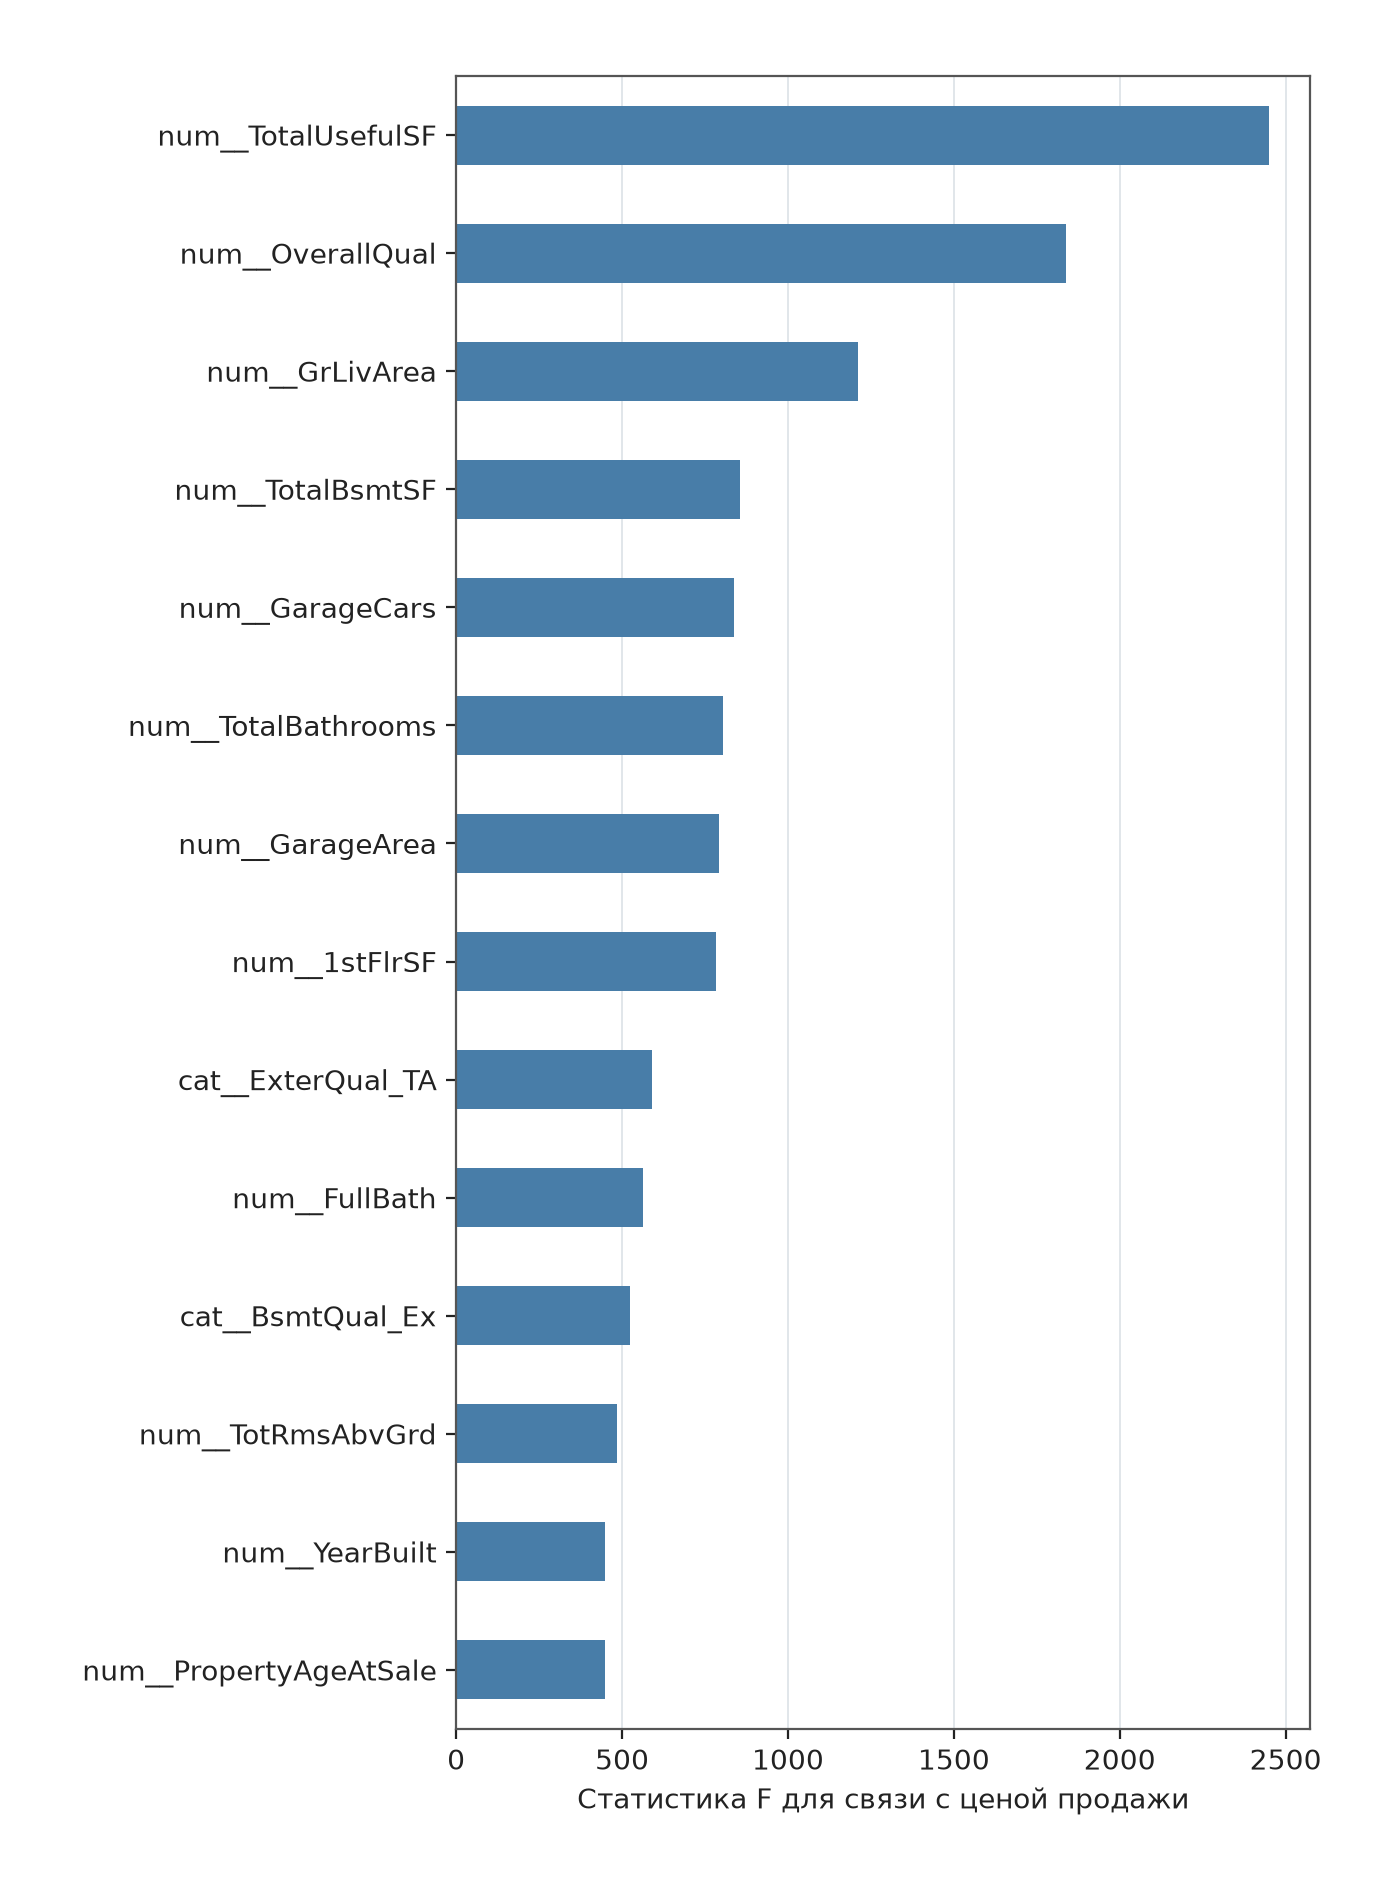

In [8]:
display(Image(filename=str(result.generated_plots["scores"])))

*Рисунок 2.2 — Наиболее информативные признаки недвижимости по статистике F.*

Высокая статистическая значимость сама по себе ещё не гарантирует улучшение прогнозирования. Некоторые характеристики сильно связаны друг с другом, например `GarageArea` (площадь гаража) и `GarageCars` (вместимость гаража в автомобилях). В дальнейшем сравним модели с полным набором и с отобранными признаками.

In [9]:
print("SelectKBest — первые 10 признаков:")
for name in result.selected_kbest[:10]:
    print(" ", name)
print("\nRFE — первые 10 признаков:")
for name in result.selected_rfe[:10]:
    print(" ", name)

SelectKBest — первые 10 признаков:
  num__OverallQual
  num__YearBuilt
  num__YearRemodAdd
  num__MasVnrArea
  num__TotalBsmtSF
  num__1stFlrSF
  num__GrLivArea
  num__FullBath
  num__TotRmsAbvGrd
  num__GarageCars

RFE — первые 10 признаков:
  num__TotalUsefulSF
  num__GrLivArea
  num__1stFlrSF
  cat__BsmtQual_Ex
  num__YearBuilt
  num__PropertyAgeAtSale
  num__YearsSinceRemodel
  num__YearRemodAdd
  cat__KitchenQual_Ex
  cat__ExterQual_Ex


## Мультиколлинеарность (VIF)

VIF показывает, насколько сильно один признак линейно связан с остальными. Высокие значения особенно важны при интерпретации коэффициентов линейной регрессии.

Сначала рассмотрим **полный набор из 14 числовых характеристик**, где сохраняются производные признаки. Затем повторим расчёт без `TotalUsefulSF` (суммарная площадь), `PropertyAgeAtSale` (возраст при продаже) и `YearsSinceRemodel` (лет после реконструкции). Эти три признака исключаются только из второго расчёта VIF. Из подготовленных данных для моделей ничего не удаляем.

In [10]:
import numpy as np
vif_full = pd.read_csv(OUTPUT_DIR / "preprocessing" / "vif.csv")
vif_reduced = pd.read_csv(OUTPUT_DIR / "preprocessing" / "vif_reduced.csv")
vif_diagnostics = pd.read_csv(OUTPUT_DIR / "preprocessing" / "vif_diagnostics.csv")
print("Проверка ранга и обусловленности:")
display(vif_diagnostics)
print("Полный набор признаков:")
display(vif_full)
print("Сокращённый набор — только для оценки VIF:")
display(vif_reduced)
for name, table in (("Полный", vif_full), ("Сокращённый", vif_reduced)):
    print(f"{name}: VIF > 10 у {(table['VIF'] > 10).sum()} признаков; "
          f"бесконечный VIF у {np.isinf(table['VIF']).sum()}")

Проверка ранга и обусловленности:


,Набор,Признаков,Ранг,Число обусловленности,Линейная зависимость
0,Полный,14,13,1.136269e+16,True
1,Сокращённый,11,11,1.916828e+01,False


Полный набор признаков:


,Признак,VIF,Интерпретация
0,TotalBsmtSF,inf,Точная линейная зависимость
1,1stFlrSF,inf,Точная линейная зависимость
2,2ndFlrSF,inf,Точная линейная зависимость
3,TotalUsefulSF,inf,Точная линейная зависимость
4,PropertyAgeAtSale,1.181539e+06,Сильная мультиколлинеарность
5,YearBuilt,1.177809e+06,Сильная мультиколлинеарность
6,YearRemodAdd,5.439785e+05,Сильная мультиколлинеарность
7,YearsSinceRemodel,5.438448e+05,Сильная мультиколлинеарность
8,GrLivArea,3.352969e+01,Сильная мультиколлинеарность
9,GarageCars,5.771531e+00,Требует внимания


Сокращённый набор — только для оценки VIF:


,Признак,VIF,Интерпретация
0,GrLivArea,31.050103,Сильная мультиколлинеарность
1,2ndFlrSF,23.802989,Сильная мультиколлинеарность
2,1stFlrSF,19.243945,Сильная мультиколлинеарность
3,GarageCars,5.767159,Требует внимания
4,GarageArea,5.385341,Требует внимания
5,TotalBsmtSF,3.683666,Умеренная или низкая
6,OverallQual,2.851307,Умеренная или низкая
7,YearBuilt,2.339274,Умеренная или низкая
8,TotalBathrooms,2.185869,Умеренная или низкая
9,YearRemodAdd,1.734437,Умеренная или низкая


Полный: VIF > 10 у 9 признаков; бесконечный VIF у 4
Сокращённый: VIF > 10 у 3 признаков; бесконечный VIF у 0


В полном наборе `TotalUsefulSF` (суммарная площадь) точно равна сумме `TotalBsmtSF` (площадь подвала), `1stFlrSF` (площадь первого этажа) и `2ndFlrSF` (площадь второго этажа). Поэтому матрица может иметь неполный ранг, а VIF для взаимозависимых характеристик становится бесконечным. Это свойство самих данных, а не ошибка библиотеки.

Сокращённый расчёт помогает увидеть остальные связи, например между `GrLivArea` (жилая площадь) и площадями этажей, либо между `GarageCars` (вместимость гаража) и `GarageArea` (площадь гаража). Даже после исключения трёх производных характеристик VIF отдельных признаков может оставаться высоким.

При построении линейной регрессии сравним полный набор с альтернативой без части взаимозависимых признаков. Удалять все признаки с высоким VIF автоматически не нужно. Это может ухудшить качество прогнозирования.

## PCA и структура подготовленных данных

Метод главных компонент показывает, как объекты располагаются в пространстве двух новых координат. PCA подбирается на тренировочной выборке, а тестовые наблюдения только преобразуются с уже найденными коэффициентами. Для визуализации можно выделить ценовые классы цветом, но они не используются при вычислении компонент.

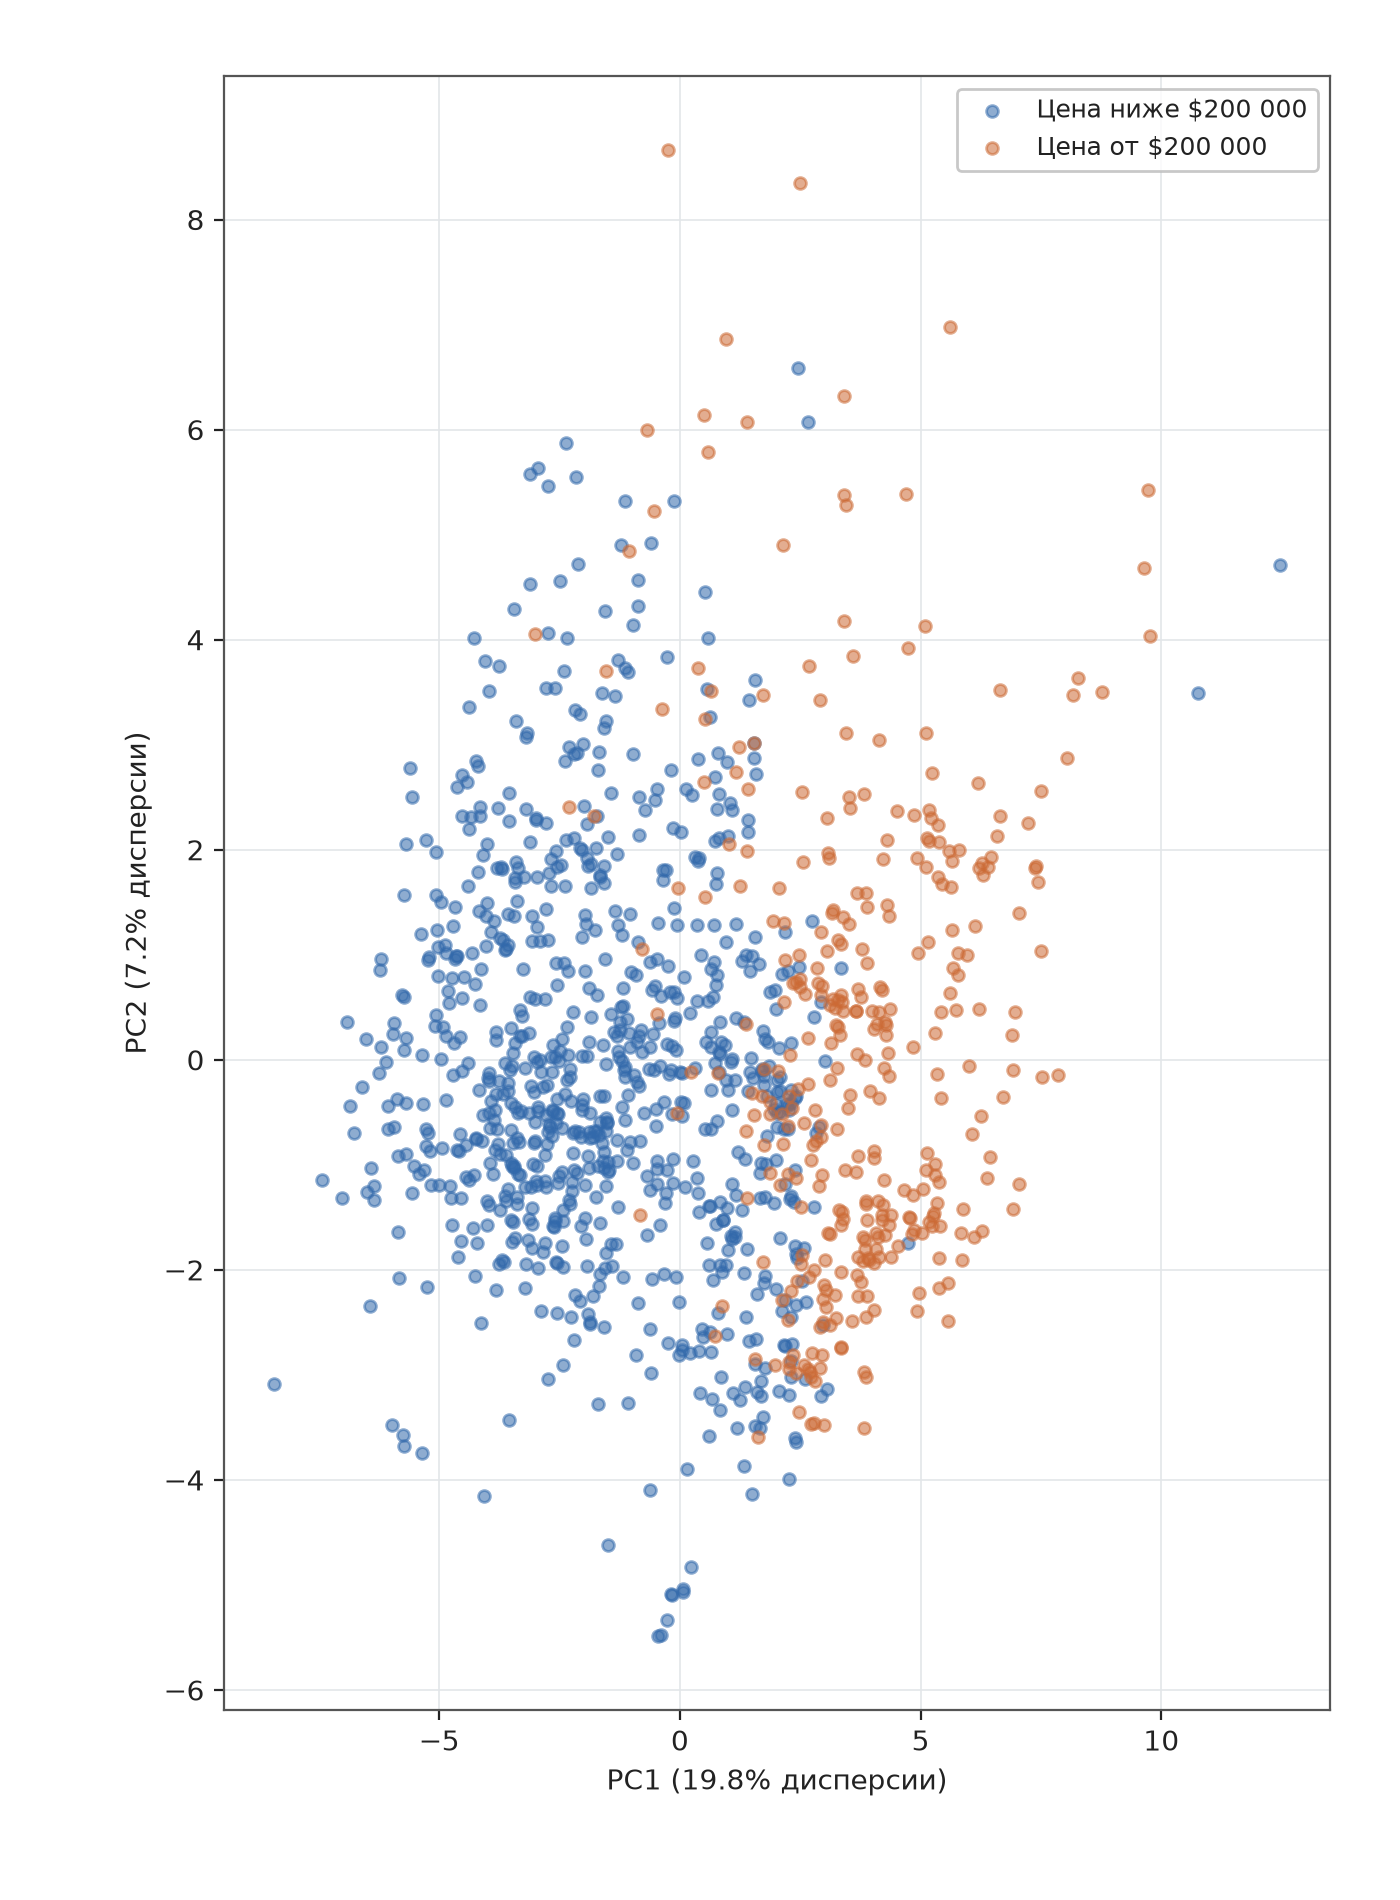

Две компоненты объясняют 27.0% дисперсии


In [11]:
display(Image(filename=str(result.generated_plots["pca"])))
print(f"Две компоненты объясняют {sum(result.pca_explained_variance):.1%} дисперсии")

*Рисунок 2.3 — Проекция подготовленных данных на первые две главные компоненты (PCA).*

Две компоненты отражают лишь часть разнообразия характеристик. Цвет точек обозначает ценовую категорию, однако при настройке PCA она не используется. По двумерному графику нельзя уверенно заключить, что существуют обособленные группы недвижимости. Отдельный анализ кластеров проведём позднее.

## Выводы

Для регрессии и классификации получены согласованные обучающие и тестовые выборки, а также целевые переменные. Исходный набор данных остался без изменений. Таблица `outlier_changes.csv` показывает фактическое количество ограниченных значений отдельно для каждой выборки.

В дальнейшем необходимо сравнить качество прогнозирования при различных стратегиях обработки выбросов и оценить пользу новых характеристик. Для линейных моделей отдельно рассмотрим влияние признаков с высокими VIF. Все операции, которым требуется обучение на данных, настроены только на тренировочной части.

In [12]:
expected = ["X_train_reg.csv", "X_test_reg.csv", "y_train_reg.csv", "y_test_reg.csv",
            "X_train_clf.csv", "X_test_clf.csv", "y_train_clf.csv", "y_test_clf.csv"]
display(pd.DataFrame({"Файл": expected,
                      "Сохранён": [(PROCESSED_DATA_DIR / name).is_file() for name in expected]}))
print("Обученный pipeline:", OUTPUT_DIR / "preprocessing" / "preprocessing_pipeline.joblib")

,Файл,Сохранён
0,X_train_reg.csv,True
1,X_test_reg.csv,True
2,y_train_reg.csv,True
3,y_test_reg.csv,True
4,X_train_clf.csv,True
5,X_test_clf.csv,True
6,y_train_clf.csv,True
7,y_test_clf.csv,True


Обученный pipeline: F:\JetBrainsProjects\PycharmProjects\house-prices-ai\outputs\preprocessing\preprocessing_pipeline.joblib
